# Финальная практическая работа
## Специализация Data Analyst

### Анализ данных сервиса «СберАвтоподписка»

Цель работы — провести подготовку и разведочный анализ данных, проверить статистические гипотезы и сформулировать рекомендации для продуктовой команды на основе поведения пользователей и конверсии в целевые действия.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.stats.proportion import proportions_ztest

## 1. Загрузка и первичное исследование данных

Для анализа используются два набора данных:

- `ga_sessions` — информация о пользовательских сессиях, источниках трафика, устройствах и географии;
- `ga_hits` — информация о действиях пользователей на сайте.

Для ускорения загрузки используются файлы формата Pickle.

In [2]:
sessions = pd.read_pickle('data/ga_sessions.pkl')

In [3]:
hits = pd.read_pickle('data/ga_hits.pkl')

### 1.1 Датасет sessions

In [4]:
sessions.head()

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,None,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,None,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


In [5]:
sessions.shape

(1860042, 18)

In [6]:
sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   client_id                 object
 2   visit_date                object
 3   visit_time                object
 4   visit_number              int64 
 5   utm_source                object
 6   utm_medium                object
 7   utm_campaign              object
 8   utm_adcontent             object
 9   utm_keyword               object
 10  device_category           object
 11  device_os                 object
 12  device_brand              object
 13  device_model              object
 14  device_screen_resolution  object
 15  device_browser            object
 16  geo_country               object
 17  geo_city                  object
dtypes: int64(1), object(17)
memory usage: 255.4+ MB


### 1.2 Датасет hits

In [7]:
hits.head()

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,None
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,None
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,None
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,None
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,None


In [8]:
hits.shape

(15726470, 11)

In [9]:
hits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15726470 entries, 0 to 15726469
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   session_id      object 
 1   hit_date        object 
 2   hit_time        float64
 3   hit_number      int64  
 4   hit_type        object 
 5   hit_referer     object 
 6   hit_page_path   object 
 7   event_category  object 
 8   event_action    object 
 9   event_label     object 
 10  event_value     object 
dtypes: float64(1), int64(1), object(9)
memory usage: 1.3+ GB


### 1.3 Анализ пропущенных значений

In [10]:
missing_values = sessions.isna().sum()
missing_percent = (missing_values / len(sessions) * 100).round(2)

missing_data = pd.DataFrame({
    'missing_values': missing_values,
    'missing_percent': missing_percent
})

missing_data.sort_values('missing_percent', ascending=False)

,missing_values,missing_percent
device_model,1843704,99.12
utm_keyword,1082061,58.17
device_os,1070138,57.53
utm_adcontent,335615,18.04
utm_campaign,219603,11.81
device_brand,118678,6.38
utm_source,97,0.01
session_id,0,0.00
client_id,0,0.00
visit_number,0,0.00


In [11]:
hits_missing_values = hits.isna().sum()
hits_missing_percent = (
    hits_missing_values / len(hits) * 100
).round(2)

hits_missing = pd.DataFrame({
    'missing_values': hits_missing_values,
    'missing_percent': hits_missing_percent
})

hits_missing.sort_values(
    'missing_percent',
    ascending=False
)

,missing_values,missing_percent
event_value,15726470,100.00
hit_time,9160322,58.25
hit_referer,6274804,39.90
event_label,3760184,23.91
session_id,0,0.00
hit_date,0,0.00
hit_number,0,0.00
hit_page_path,0,0.00
hit_type,0,0.00
event_action,0,0.00


### 1.4 Проверка дубликатов и идентификаторов сессий

In [12]:
print('Дубликаты в sessions:', sessions.duplicated().sum())
print('Дубликаты в hits:', hits.duplicated().sum())

Дубликаты в sessions: 0
Дубликаты в hits: 0


In [13]:
print('Строк в sessions:', len(sessions))
print('Уникальных session_id в sessions:', sessions['session_id'].nunique())

print('Строк в hits:', len(hits))
print('Уникальных session_id в hits:', hits['session_id'].nunique())

Строк в sessions: 1860042
Уникальных session_id в sessions: 1860042
Строк в hits: 15726470
Уникальных session_id в hits: 1734610


### 1.5 Проверка связи между наборами данных

Наборы данных связываются по `session_id`. Проверим наличие сессий, которые представлены только в одном из двух датасетов.

In [14]:
hits_sessions = set(hits['session_id'])
sessions_ids = set(sessions['session_id'])

print('Сессий в sessions:', len(sessions_ids))
print('Сессий в hits:', len(hits_sessions))
print('Есть в sessions, но нет в hits:', len(sessions_ids - hits_sessions))
print('Есть в hits, но нет в sessions:', len(hits_sessions - sessions_ids))

del hits_sessions, sessions_ids

Сессий в sessions: 1860042
Сессий в hits: 1734610
Есть в sessions, но нет в hits: 127776
Есть в hits, но нет в sessions: 2344


Часть сессий присутствует только в одном из наборов данных. Поэтому при дальнейшем анализе основной таблицей используется `sessions`, а информация из `hits` применяется для определения целевых действий и анализа просмотренных автомобилей.

## 2. Подготовка данных

На данном этапе выполняется базовая очистка данных, преобразование типов и формирование признака целевого действия.

In [15]:
sessions.drop(columns=['device_model'], inplace=True)

In [16]:
hits.drop(columns=['event_value'], inplace=True)

Столбец `device_model` удалён из `sessions`, поскольку более 99% его значений отсутствуют.

Столбец `event_value` удалён из `hits`, поскольку он полностью состоит из пропущенных значений.

### 2.1 Преобразование даты

In [17]:
sessions['visit_date'] = pd.to_datetime(sessions['visit_date'])

In [18]:
print('Начало периода:', sessions['visit_date'].min())
print('Конец периода:', sessions['visit_date'].max())
print('Количество дней:', sessions['visit_date'].nunique())

Начало периода: 2021-05-19 00:00:00
Конец периода: 2021-12-31 00:00:00
Количество дней: 226


### 2.2 Формирование целевой переменной

Сессия считается конверсионной, если в рамках неё произошло хотя бы одно целевое действие.

In [19]:
target_actions = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click'
]

In [20]:
hits.loc[
    hits['event_action'].isin(target_actions),
    'event_action'
].value_counts()

event_action
sub_car_claim_click                 37928
sub_open_dialog_click               25870
sub_submit_success                  18439
sub_car_claim_submit_click          12359
sub_call_number_click                3653
sub_callback_submit_click            3074
sub_car_request_submit_click         2966
sub_custom_question_submit_click      619
Name: count, dtype: int64

In [21]:
target_sessions = (
    hits.loc[hits['event_action'].isin(target_actions), 'session_id']
    .drop_duplicates()
)

In [22]:
sessions['target'] = sessions['session_id'].isin(target_sessions).astype(int)

In [23]:
sessions['target'].value_counts()

target
0    1809728
1      50314
Name: count, dtype: int64

In [24]:
overall_cr = sessions['target'].mean() * 100

print(f'Общий Conversion Rate: {overall_cr:.2f}%')

Общий Conversion Rate: 2.70%


Общий Conversion Rate в целевые действия составляет **2.70%**.

## 3. Разведочный анализ данных

In [25]:
daily_sessions = (
    sessions.groupby('visit_date')
    .size()
    .reset_index(name='sessions_count')
)

daily_sessions.head()

,visit_date,sessions_count
0,2021-05-19,877
1,2021-05-21,1110
2,2021-05-22,986
3,2021-05-23,1246
4,2021-05-24,39453


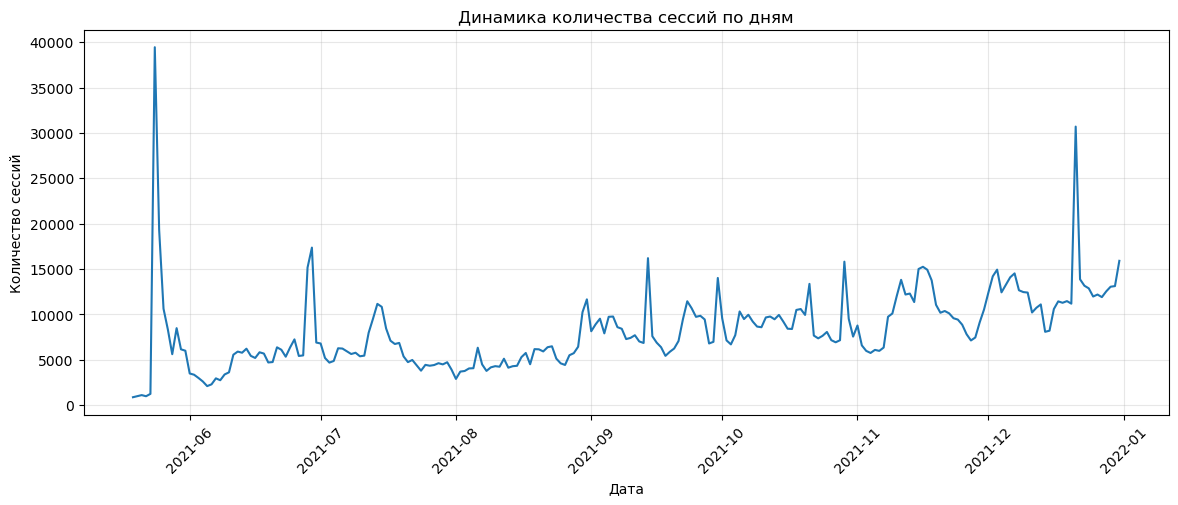

In [26]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sessions['visit_date'],
    daily_sessions['sessions_count']
)

plt.title('Динамика количества сессий по дням')
plt.xlabel('Дата')
plt.ylabel('Количество сессий')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

Количество сессий в течение рассматриваемого периода в целом увеличивается. Также наблюдаются отдельные выраженные всплески пользовательской активности.

In [27]:
device_cr = (
    sessions.groupby('device_category')
    .agg(
        sessions_count=('session_id', 'count'),
        conversions=('target', 'sum'),
        cr=('target', 'mean')
    )
    .reset_index()
)

device_cr['cr'] = device_cr['cr'] * 100

device_cr.sort_values('cr', ascending=False)

,device_category,sessions_count,conversions,cr
0,desktop,366863,11513,3.138229
1,mobile,1474871,38379,2.602194
2,tablet,18308,422,2.305003


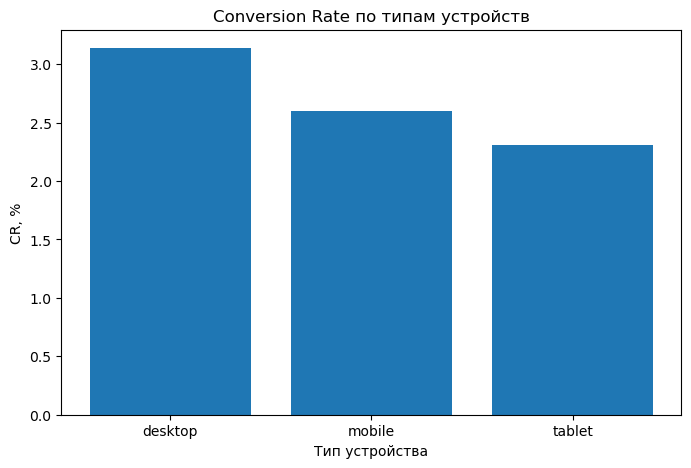

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    device_cr['device_category'],
    device_cr['cr']
)

plt.title('Conversion Rate по типам устройств')
plt.xlabel('Тип устройства')
plt.ylabel('CR, %')

plt.show()

In [29]:
device_stats = (
    sessions['device_category']
    .value_counts()
    .reset_index()
)

device_stats.columns = ['device_category', 'sessions_count']

device_stats

,device_category,sessions_count
0,mobile,1474871
1,desktop,366863
2,tablet,18308


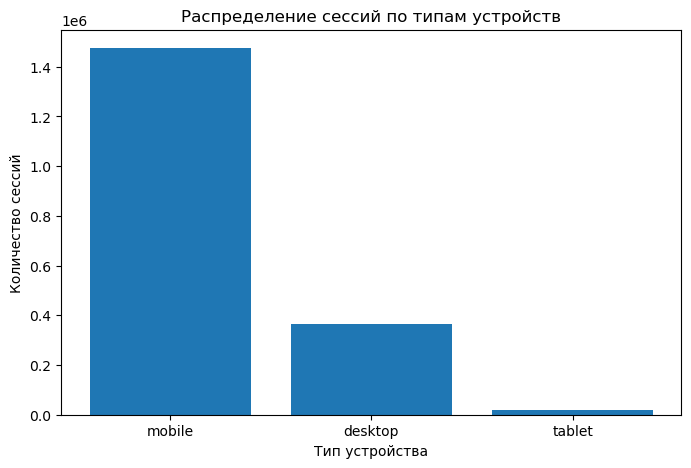

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(
    device_stats['device_category'],
    device_stats['sessions_count']
)

plt.title('Распределение сессий по типам устройств')
plt.xlabel('Тип устройства')
plt.ylabel('Количество сессий')

plt.show()

In [31]:
top_cities = sessions['geo_city'].value_counts().head(10)

top_cities

geo_city
Moscow              805329
Saint Petersburg    296788
(not set)            78172
Yekaterinburg        35788
Krasnodar            32243
Kazan                29531
Samara               24992
Nizhny Novgorod      22227
Ufa                  21679
Novosibirsk          21568
Name: count, dtype: int64

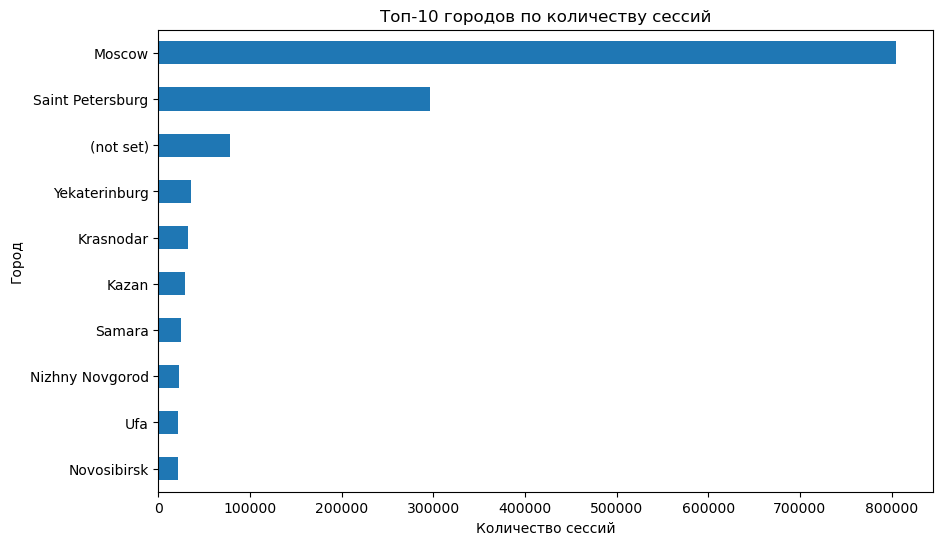

In [32]:
plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind='barh')

plt.title('Топ-10 городов по количеству сессий')
plt.xlabel('Количество сессий')
plt.ylabel('Город')

plt.show()

In [33]:
sessions['geo_country'].value_counts().head(10)

geo_country
Russia           1800565
United States      11784
Ukraine             9012
Ireland             4034
Belarus             3636
Sweden              2694
Kazakhstan          2279
Germany             2232
Turkey              1953
Netherlands         1549
Name: count, dtype: int64

In [34]:
top_sources = sessions['utm_source'].value_counts().head(15)

top_sources

utm_source
ZpYIoDJMcFzVoPFsHGJL    578290
fDLlAcSmythWSCVMvqvL    300575
kjsLglQLzykiRbcDiGcD    266354
MvfHsxITijuriZxsqZqt    186199
BHcvLfOaCWvWTykYqHVe    116320
bByPQxmDaMXgpHeypKSM    102287
QxAxdyPLuQMEcrdZWdWb     51415
aXQzDWsJuGXeBXexNHjc     31152
jaSOmLICuBzCFqHfBdRg     29241
RmEBuqrriAfAVsLQQmhk     28055
vFcAhRxLfOWKhvxjELkx     24413
PlbkrSYoHuZBWfYjYnfw     20792
hTjLvqNxGggkGnxSCaTm     14598
gDBGzjFKYabGgSPZvrDH     13565
fgymSoTvjKPEgaIJqsiH      9625
Name: count, dtype: int64

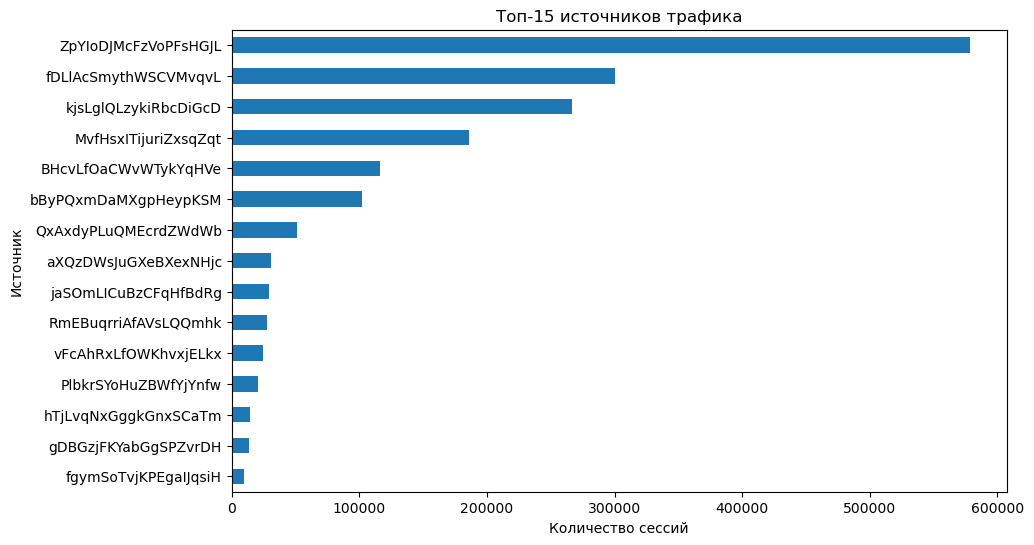

In [35]:
plt.figure(figsize=(10, 6))

top_sources.sort_values().plot(kind='barh')

plt.title('Топ-15 источников трафика')
plt.xlabel('Количество сессий')
plt.ylabel('Источник')

plt.show()

### Вывод по EDA

- Основная часть трафика приходится на мобильные устройства.
- Desktop показывает более высокий CR, чем Mobile и Tablet.
- Наибольший объём трафика приходится на Москву и Санкт-Петербург.
- Большинство сессий относится к России.
- Трафик распределён между источниками неравномерно: несколько источников обеспечивают значительную часть посещений.
- В динамике наблюдается рост трафика и отдельные выраженные всплески активности.

## 4. Проверка статистических гипотез

In [36]:
alpha = 0.05

### 4.1 Органический и платный трафик

Проверим, различается ли коэффициент конверсии между органическим
и платным трафиком.

**H₀:** коэффициенты конверсии органического и платного трафика равны.

**H₁:** коэффициенты конверсии органического и платного трафика различаются.

Уровень значимости: α = 0,05.

In [37]:
organic_medium = ['organic', 'referral', '(none)']

sessions['traffic_type'] = np.where(
    sessions['utm_medium'].isin(organic_medium),
    'organic',
    'paid'
)

In [38]:
traffic_stats = sessions.groupby('traffic_type').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

traffic_stats['cr'] = (
    traffic_stats['conversions'] /
    traffic_stats['sessions_count'] * 100
)

traffic_stats

,sessions_count,conversions,cr
traffic_type,,,
organic,515659,20812,4.036001
paid,1344383,29502,2.194464


In [39]:
count = traffic_stats['conversions'].values
nobs = traffic_stats['sessions_count'].values

z_stat, p_value = proportions_ztest(count, nobs)

print(f'Z-statistic: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

if p_value < 0.05:
    print('Отвергаем H0: различия статистически значимы.')
else:
    print('Не отвергаем H0: статистически значимых различий не обнаружено.')

Z-statistic: 69.3000
p-value: 0.000000
Отвергаем H0: различия статистически значимы.


### Вывод

Коэффициент конверсии органического трафика составляет около 4,04%,
а платного — около 2,19%.

Полученное значение p-value < 0,05, поэтому нулевая гипотеза отвергается.
Различия между коэффициентами конверсии органического и платного
трафика являются статистически значимыми.

Таким образом, органический трафик конвертируется в целевое действие
статистически значимо лучше платного.

### 4.2 Mobile и Desktop

Проверим, различается ли коэффициент конверсии пользователей
мобильных и настольных устройств.

**H₀:** коэффициенты конверсии mobile и desktop равны.

**H₁:** коэффициенты конверсии mobile и desktop различаются.

Уровень значимости: α = 0,05.

In [40]:
device_stats = sessions.groupby('device_category').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

device_stats['cr'] = (
    device_stats['conversions'] /
    device_stats['sessions_count'] * 100
)

device_stats

,sessions_count,conversions,cr
device_category,,,
desktop,366863,11513,3.138229
mobile,1474871,38379,2.602194
tablet,18308,422,2.305003


In [41]:
mobile = sessions[sessions['device_category'] == 'mobile']
desktop = sessions[sessions['device_category'] == 'desktop']

count = [
    mobile['target'].sum(),
    desktop['target'].sum()
]

nobs = [
    len(mobile),
    len(desktop)
]

z_stat, p_value = proportions_ztest(count, nobs)

print(f'CR mobile: {mobile["target"].mean() * 100:.2f}%')
print(f'CR desktop: {desktop["target"].mean() * 100:.2f}%')
print(f'Z-statistic: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

if p_value < 0.05:
    print('Отвергаем H0: CR mobile и desktop статистически различается.')
else:
    print('Не отвергаем H0: статистически значимых различий не обнаружено.')

CR mobile: 2.60%
CR desktop: 3.14%
Z-statistic: -17.8966
p-value: 0.000000
Отвергаем H0: CR mobile и desktop статистически различается.


### Вывод

CR пользователей desktop составляет около 3,14%, тогда как
CR пользователей mobile — около 2,60%.

Полученное значение p-value < 0,05, поэтому нулевая гипотеза отвергается.
Различие между коэффициентами конверсии mobile и desktop
является статистически значимым.

Несмотря на то что мобильные устройства обеспечивают значительно
больший объём трафика, пользователи desktop статистически значимо
чаще совершают целевое действие.

### 4.3 Города присутствия и остальные регионы

Проверим, различается ли коэффициент конверсии пользователей
из городов присутствия компании и пользователей из остальных регионов.

**H₀:** коэффициенты конверсии двух групп равны.

**H₁:** коэффициенты конверсии двух групп различаются.

Уровень значимости: α = 0,05.

In [42]:
presence_cities = [
    'Moscow',
    'Saint Petersburg'
]

sessions['location_group'] = np.where(
    sessions['geo_city'].isin(presence_cities),
    'presence_cities',
    'other_regions'
)

In [43]:
location_stats = sessions.groupby('location_group').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

location_stats['cr'] = (
    location_stats['conversions'] /
    location_stats['sessions_count'] * 100
)

location_stats

,sessions_count,conversions,cr
location_group,,,
other_regions,757925,19572,2.582314
presence_cities,1102117,30742,2.789359


In [44]:
count = location_stats['conversions'].values
nobs = location_stats['sessions_count'].values

z_stat, p_value = proportions_ztest(count, nobs)

print(f'Z-statistic: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

if p_value < 0.05:
    print(
        'Отвергаем H0: CR городов присутствия и других регионов '
        'статистически различается.'
    )
else:
    print(
        'Не отвергаем H0: статистически значимых различий '
        'не обнаружено.'
    )

Z-statistic: -8.5527
p-value: 0.000000
Отвергаем H0: CR городов присутствия и других регионов статистически различается.


### Вывод

CR пользователей из городов присутствия составляет около 2,79%,
а пользователей из остальных регионов — около 2,58%.

Полученное значение p-value < 0,05, поэтому нулевая гипотеза отвергается.
Различие между коэффициентами конверсии является статистически значимым.

Таким образом, пользователи из городов присутствия компании
статистически значимо чаще совершают целевое действие, хотя абсолютная
разница в CR невелика — около 0,21 процентного пункта.

### 4.4 Общий вывод по проверке гипотез

Все три проверенные гипотезы показали статистически значимые различия
при уровне значимости α = 0,05:

1. **Органический и платный трафик:** органический трафик имеет более высокий
   CR — около 4,04% против 2,19%.

2. **Desktop и mobile:** desktop имеет более высокий CR —
   около 3,14% против 2,60%.

3. **Города присутствия и остальные регионы:** города присутствия имеют
   несколько более высокий CR — около 2,79% против 2,58%.

При этом статистическая значимость не обязательно означает большое
практическое различие. Особенно это заметно в географической гипотезе,
где при большом объёме данных статистически значимой оказалась
сравнительно небольшая разница в коэффициенте конверсии.

## 5. Анализ целевого трафика

### 5.1 Анализ источников трафика

Проанализируем источники привлечения пользователей и определим,
какие из них обеспечивают наибольший объём трафика и наиболее высокую конверсию.

In [45]:
source_stats = sessions.groupby('utm_source').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

source_stats['cr'] = (
    source_stats['conversions'] / source_stats['sessions_count'] * 100
)

source_stats = source_stats.sort_values(
    'sessions_count',
    ascending=False
)

source_stats.head(15)

,sessions_count,conversions,cr
utm_source,,,
ZpYIoDJMcFzVoPFsHGJL,578290,15998,2.766432
fDLlAcSmythWSCVMvqvL,300575,10531,3.503618
kjsLglQLzykiRbcDiGcD,266354,6293,2.362645
MvfHsxITijuriZxsqZqt,186199,2249,1.207848
BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345
bByPQxmDaMXgpHeypKSM,102287,5557,5.432753
QxAxdyPLuQMEcrdZWdWb,51415,1404,2.730721
aXQzDWsJuGXeBXexNHjc,31152,1827,5.864792
jaSOmLICuBzCFqHfBdRg,29241,401,1.371362


In [46]:
source_stats.sort_values(
    'cr',
    ascending=False
).head(15)

,sessions_count,conversions,cr
utm_source,,,
YpBKcihLLfFjWuxOLfvW,1,1,100.000000
fJCYsujgSxIHFbOmgDdN,8,7,87.500000
XzfzEBYZWgSDtJNXOadn,2,1,50.000000
CqeIpFwJscTsZoYXdHsP,2,1,50.000000
yxJKymlSGVuKIPTxbysx,3,1,33.333333
LIWKeifdTCbuNeniIUqm,57,17,29.824561
JcVHXwVSrnfIuOMMEkrJ,4,1,25.000000
hONgZhBaHwLGhvJSefNE,5,1,20.000000
hIlpdXTVGwzYWIOqvhtN,5,1,20.000000


In [47]:
source_stats[
    source_stats['sessions_count'] >= 1000
].sort_values('cr', ascending=False).head(15)

,sessions_count,conversions,cr
utm_source,,,
oZCzWSykfixnjMPDNjSU,3143,260,8.272351
BKeImrJuRDZcHiSSTdzm,1464,98,6.693989
aXQzDWsJuGXeBXexNHjc,31152,1827,5.864792
bByPQxmDaMXgpHeypKSM,102287,5557,5.432753
DnEUulZAecfGPvdtZBYS,1420,76,5.352113
klTrhUaShgnjIbaPmqjc,1197,42,3.508772
fDLlAcSmythWSCVMvqvL,300575,10531,3.503618
WEXkMlsnJodrzBgKJBpG,1003,35,3.489531
BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345


### Вывод

Источники трафика существенно различаются как по объёму привлечённых
пользователей, так и по уровню конверсии.

Наибольший объём трафика обеспечивает источник `ZpYIoDJMcFzVoPFsHGJL` —
578 290 сессий при CR около 2,77%.

При этом большой объём трафика не всегда означает высокую эффективность:
некоторые менее крупные источники демонстрируют более высокий CR.

При оценке эффективности источников необходимо учитывать одновременно
объём трафика и конверсию, поскольку высокий CR на небольшом количестве
сессий может быть нестабильным.

### 5.2 Анализ рекламных кампаний

Рассмотрим эффективность рекламных кампаний по количеству сессий,
конверсий и коэффициенту конверсии.

In [48]:
campaign_stats = sessions.groupby('utm_campaign').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

campaign_stats['cr'] = (
    campaign_stats['conversions'] /
    campaign_stats['sessions_count'] * 100
)

campaign_stats = campaign_stats.sort_values(
    'sessions_count',
    ascending=False
)

campaign_stats.head(15)

,sessions_count,conversions,cr
utm_campaign,,,
LTuZkdKfxRGVceoWkVyg,463481,19006,4.100707
LEoPHuyFvzoNfnzGgfcd,324044,9348,2.884793
FTjNLDyTrXaWYgZymFkV,247360,2447,0.989246
gecBYcKZCPMcVYdSSzKP,134042,4545,3.390728
TmThBvoCcwkCZZUWACYq,26597,123,0.462458
XHNUiSKKGTEpSAlaVMFQ,24524,401,1.635133
okTXSMadDkjvntEHzIjp,24511,77,0.314145
SgIUDYUKnyWHVowUOqid,22841,373,1.633028
sbJRYgVfvcnqKJNDDYIr,20188,575,2.848227


In [49]:
campaign_stats[
    campaign_stats['sessions_count'] >= 1000
].sort_values('cr', ascending=False).head(15)

,sessions_count,conversions,cr
utm_campaign,,,
EiQppLFrUZrUsjXVulLg,1252,110,8.785942
WJUKqfeOrjXIOHjgcgdR,1146,76,6.631763
DsqwamlMwRgMTyspCjFR,2829,172,6.079887
YDIkQmcjRkpdxGbLLtNN,2651,161,6.073180
QejVLgNgzFMqjZPsnfxa,1724,89,5.162413
ngkgBNjlzLYBofkljaBo,1615,73,4.520124
hkvDVxqLOzGjGaoNiNzN,4445,184,4.139483
LTuZkdKfxRGVceoWkVyg,463481,19006,4.100707
kwdmElMUPDZaLQdgjcsI,1107,45,4.065041


### Вывод

Рекламные кампании заметно различаются по эффективности.

Кампания `LTuZkdKfxRGVceoWkVyg` обеспечивает наибольший объём трафика —
463 481 сессию — и при этом имеет CR около 4,10%.

Некоторые кампании показывают более высокий CR, однако имеют значительно
меньший объём трафика. Поэтому при принятии маркетинговых решений необходимо
оценивать не только CR, но и количество сессий и абсолютное число конверсий.

### 5.3 Анализ конверсии по типам устройств

Сравним количество сессий и конверсию пользователей
с разных типов устройств.

In [50]:
device_stats = sessions.groupby('device_category').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

device_stats['cr'] = (
    device_stats['conversions'] /
    device_stats['sessions_count'] * 100
)

device_stats.sort_values('sessions_count', ascending=False)

,sessions_count,conversions,cr
device_category,,,
mobile,1474871,38379,2.602194
desktop,366863,11513,3.138229
tablet,18308,422,2.305003


### Вывод

Основная часть трафика приходится на мобильные устройства —
около 1,47 млн сессий.

При этом пользователи desktop имеют более высокий CR — около 3,14%
против 2,60% у mobile и 2,31% у tablet.

Таким образом, мобильные устройства обеспечивают основной объём трафика,
однако desktop-трафик конвертируется эффективнее.

### 5.4 Анализ конверсии по городам

Рассмотрим города с наибольшим количеством сессий и сравним
их коэффициенты конверсии.

In [51]:
city_stats = sessions.groupby('geo_city').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

city_stats['cr'] = (
    city_stats['conversions'] /
    city_stats['sessions_count'] * 100
)

city_stats.sort_values(
    'sessions_count',
    ascending=False
).head(15)

,sessions_count,conversions,cr
geo_city,,,
Moscow,805329,23629,2.934080
Saint Petersburg,296788,7113,2.396660
(not set),78172,1588,2.031418
Yekaterinburg,35788,887,2.478484
Krasnodar,32243,1081,3.352666
Kazan,29531,1139,3.856964
Samara,24992,727,2.908931
Nizhny Novgorod,22227,559,2.514959
Ufa,21679,639,2.947553


In [52]:
city_stats[
    city_stats['sessions_count'] >= 1000
].sort_values('cr', ascending=False).head(15)

,sessions_count,conversions,cr
geo_city,,,
Domodedovo,4038,263,6.513125
Makhachkala,2607,139,5.331799
Nalchik,1099,52,4.731574
Vladikavkaz,1149,54,4.699739
Stavropol,4377,180,4.112406
Kazan,29531,1139,3.856964
Korolyov,4047,145,3.582901
Cheboksary,2320,83,3.577586
Sochi,8972,316,3.522069


### Вывод

Основная часть трафика сосредоточена в Москве и Санкт-Петербурге.
Москва значительно лидирует по количеству сессий — более 805 тыс.

При этом высокий объём трафика не всегда соответствует максимальному CR.
Например, Казань показывает CR около 3,86%, а Краснодар — около 3,35%,
что выше показателей Москвы и Санкт-Петербурга.

Это указывает на различия в эффективности трафика между городами.

### 5.5 Анализ интереса к автомобилям

На основе посещений карточек автомобилей определим наиболее популярные
модели и сравним их конверсию.

In [53]:
car_hits = hits[
    hits['hit_page_path'].str.contains(
        '/cars/all/',
        na=False
    )
].copy()

In [54]:
car_hits[['brand', 'model']] = (
    car_hits['hit_page_path']
    .str.extract(r'/cars/all/([^/]+)/([^/?]+)')
)

car_hits = car_hits.dropna(subset=['brand', 'model'])

car_hits['car'] = (
    car_hits['brand'].str.title()
    + ' '
    + car_hits['model'].str.title()
)

In [55]:
car_stats = car_hits.groupby('car').agg(
    sessions_count=('session_id', 'nunique')
)

car_conversions = (
    car_hits[['session_id', 'car']]
    .drop_duplicates()
    .merge(
        sessions[['session_id', 'target']],
        on='session_id',
        how='left'
    )
    .groupby('car')
    .agg(conversions=('target', 'sum'))
)

car_stats = car_stats.join(car_conversions)

car_stats['cr'] = (
    car_stats['conversions'] /
    car_stats['sessions_count'] * 100
)

car_stats.sort_values(
    'sessions_count',
    ascending=False
).head(20)

,sessions_count,conversions,cr
car,,,
Skoda Rapid,56865,4043.0,7.109822
Lada-Vaz Vesta,49416,3335.0,6.748826
Volkswagen Polo,41302,3423.0,8.287734
Skoda Karoq,25527,1328.0,5.202335
Mercedes-Benz E-Klasse,22683,916.0,4.038267
Nissan Qashqai,20659,912.0,4.414541
Nissan X-Trail,11839,497.0,4.197990
Kia Rio,11555,1047.0,9.061013
Renault Duster,10956,402.0,3.669222


In [56]:
car_stats[
    car_stats['sessions_count'] >= 1000
].sort_values('cr', ascending=False).head(20)

,sessions_count,conversions,cr
car,,,
Kia Rio,11555,1047.0,9.061013
Toyota Camry,9736,852.0,8.751027
Volkswagen Polo,41302,3423.0,8.287734
Toyota Corolla,3209,264.0,8.226862
Hyundai Solaris,2239,174.0,7.771326
Kia Seltos,9124,686.0,7.518632
Skoda Rapid,56865,4043.0,7.109822
Skoda Octavia,10078,713.0,7.074816
Lada-Vaz Vesta,49416,3335.0,6.748826


### Вывод

Наибольший интерес пользователей среди рассмотренных автомобилей вызывают
Skoda Rapid, Lada-Vaz Vesta и Volkswagen Polo.

При этом Volkswagen Polo демонстрирует особенно высокий CR — около 8,29%.
Высокие значения CR также наблюдаются у Kia Rio, Toyota Camry,
Hyundai Solaris и ряда других моделей.

Следовательно, данные о просмотрах конкретных автомобилей могут быть
полезны для определения моделей с высоким пользовательским интересом
и высокой вероятностью целевого действия.

### 5.6 Анализ трафика из социальных сетей

Сравним конверсию трафика из социальных сетей
с остальными источниками трафика.

In [57]:
social_sources = [
    'QxAxdyPLuQMEcrdZWdWb',
    'MvfHsxITijuriZxsqZqt',
    'ISrKoXQCxqqYvAZICvjs',
    'IZEXUFLARCUMynmHNBGo',
    'PlbkrSYoHuZBWfYjYnfw',
    'gVRrcxiDQubJiljoTbGm'
]

sessions['social_group'] = np.where(
    sessions['utm_source'].isin(social_sources),
    'social',
    'other'
)

In [58]:
social_stats = sessions.groupby('social_group').agg(
    sessions_count=('session_id', 'count'),
    conversions=('target', 'sum')
)

social_stats['cr'] = (
    social_stats['conversions'] /
    social_stats['sessions_count'] * 100
)

social_stats

,sessions_count,conversions,cr
social_group,,,
other,1585815,46293,2.919193
social,274227,4021,1.466303


In [59]:
social = sessions[
    sessions['social_group'] == 'social'
]

other = sessions[
    sessions['social_group'] == 'other'
]

count = np.array([
    social['target'].sum(),
    other['target'].sum()
])

nobs = np.array([
    len(social),
    len(other)
])

z_stat, p_value = proportions_ztest(count, nobs)

print(f'CR social: {social["target"].mean() * 100:.2f}%')
print(f'CR other: {other["target"].mean() * 100:.2f}%')
print(f'Z-statistic: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

CR social: 1.47%
CR other: 2.92%
Z-statistic: -43.3036
p-value: 0.000000


### Вывод

Трафик из социальных сетей имеет существенно более низкую конверсию:
около 1,47% против 2,92% у остальных источников.

Проверка статистической гипотезы показала, что данное различие
статистически значимо (p-value < 0,001).

Таким образом, по имеющимся данным социальный трафик конвертируется
в целевое действие хуже остальных каналов.

# 6. Итоговые выводы и рекомендации

В ходе анализа были исследованы пользовательские сессии и действия
на сайте СберАвтоподписки за период с 19 мая по 31 декабря 2021 года.

Общий коэффициент конверсии в целевое действие составил около 2,70%.

### Основные результаты

1. Платный трафик имеет CR около 2,19%, тогда как органический —
   около 4,04%. Различие статистически значимо.

2. Основной объём трафика приходится на мобильные устройства,
   однако desktop показывает более высокий CR:
   3,14% против 2,60% у mobile. Различие статистически значимо.

3. Города присутствия показывают CR около 2,79%, тогда как остальные
   регионы — около 2,58%. Различие статистически значимо.

4. Трафик из социальных сетей показывает более низкий CR —
   около 1,47% против 2,92% у остальных источников.

5. Источники и рекламные кампании существенно различаются по эффективности.
   При их оценке необходимо учитывать одновременно объём трафика,
   количество конверсий и CR.

6. Основной географический объём трафика приходится на Москву
   и Санкт-Петербург, однако некоторые менее крупные города показывают
   более высокий коэффициент конверсии.

7. Среди наиболее популярных автомобилей выделяются Skoda Rapid,
   Lada-Vaz Vesta и Volkswagen Polo. Volkswagen Polo при этом показывает
   высокий CR — около 8,29%.

### Рекомендации

- Оптимизировать платные рекламные каналы, поскольку их конверсия
  существенно ниже органического трафика.
- Дополнительно исследовать причины более низкой конверсии mobile,
  несмотря на то что мобильные устройства обеспечивают основную часть трафика.
- При распределении рекламного бюджета учитывать не только объём трафика,
  но и CR отдельных источников и кампаний.
- Исследовать потенциал городов с относительно высоким CR для
  дополнительного привлечения пользователей.
- Пересмотреть эффективность продвижения в социальных сетях,
  поскольку данный канал показывает более низкую конверсию.
- Учитывать интерес пользователей к конкретным моделям автомобилей
  при формировании рекламных предложений.